# Evaluate DM-electron scattering rates
Ionization of Xenon by DM-electron scattering for the non-relativistic EFT of [Catena, Emken, Spaldin, Tarantino, arXiv:1912.08204](https://arxiv.org/abs/1912.08204):
  - amplitude $\mathcal{M} = \sum_i \left(c_i^s + \frac{q_\text{ref}^2}{q^2} c_i^\ell\right)\langle\mathcal{O}_i\rangle$, with dimensionless contact ($c_i^s$) and long-range ($c_i^\ell$) couplings and $q_\text{ref} = \alpha m_e$;
  - rate $\frac{dR}{d\ln E_e} = \frac{n_\chi}{128\pi m_\chi^2 m_e^2}\int dq\, q \sum_{j=1}^4 \langle R_j\rangle\, W_j(k', q)$, with the DM responses $R_j$ (functions of $q$ and $v_\text{el}^\perp$) and the atomic responses $W_1 \dots W_4$ of the 11 Xenon shells (the paper uses the 5 outer ones: 4s, 4p, 4d, 5s, 5p);
  - the velocity average uses $\eta_0 = \int d^3v\, f/v$ and, for the operators depending on $v_\text{el}^\perp$, $\int d^3 v\, f\, v$: the halo table must be written with `i=2`;
  - detector response: XENON10 (7 S2 bins) and XENON1T (S2-only data release response and mass dependent ROI).

MadDM only uses the SI/SD path ($c_1^s$, $c_4^s$) through `rapidd.calc_dRdE.DDrate_electron_save`.

In [1]:
import numpy as np
import rapidd
import matplotlib.pyplot as plt

In [2]:
# Halo of arXiv:1912.08204: SHM with v0 = 220 km/s, vesc = 544 km/s, v_E = 244 km/s, rho = 0.4 GeV/cm^3
halo_table = '../lib/halo_table/halo_table_SHM_1912.08204.dat'
do_calculate_halo = False  # the table is shipped with RAPIDD
if do_calculate_halo:
    rapidd.write_paper_halo(halo_table)  # = rapidd.calc_halo(halo_table, vesc=544., v0=220., ve=244., i=2)
rapidd.read_halo(halo_table)
rapidd.read_atomic_responses()  # W_1 ... W_4 of the 11 Xenon shells

rhoDM = rapidd.PAPER_HALO['rhoDM']  # GeV/cm^3
jchi = 0.5                          # DM spin
shells = rapidd.XE_SHELLS_PAPER     # 4s, 4p, 4d, 5s, 5p (None: all the 11 shells, as in MadDM)
YR = 365.25                         # days per year

## Evaluate the NREFT rates
Calculate the ionization spectra setting the non-relativistic EFT coefficients of the operators of Tab. I (DM spin 1/2). $\mathcal{O}_2$ and $\mathcal{O}_{16}$ are excluded as in the paper, $\mathcal{O}_{17} \dots \mathcal{O}_{20}$ (spin-1 DM) do not enter the DM responses.
\begin{align}
\mathcal{O}_1 &= \mathbf{1}_\chi \mathbf{1}_e; &
\mathcal{O}_9 &= i\mathbf{S}_\chi \cdot \left(\mathbf{S}_e \times \frac{\mathbf{q}}{m_e}\right); \\
\mathcal{O}_3 &= i\mathbf{S}_e \cdot \left(\frac{\mathbf{q}}{m_e} \times \mathbf{v}_\text{el}^\perp\right); &
\mathcal{O}_{10} &= i\mathbf{S}_e \cdot \frac{\mathbf{q}}{m_e}; \\
\mathcal{O}_4 &= \mathbf{S}_\chi \cdot \mathbf{S}_e; &
\mathcal{O}_{11} &= i\mathbf{S}_\chi \cdot \frac{\mathbf{q}}{m_e}; \\
\mathcal{O}_5 &= i\mathbf{S}_\chi \cdot \left(\frac{\mathbf{q}}{m_e} \times \mathbf{v}_\text{el}^\perp\right); &
\mathcal{O}_{12} &= \mathbf{S}_\chi \cdot \left(\mathbf{S}_e \times \mathbf{v}_\text{el}^\perp\right); \\
\mathcal{O}_6 &= \left(\mathbf{S}_\chi \cdot \frac{\mathbf{q}}{m_e}\right)\left(\mathbf{S}_e \cdot \frac{\mathbf{q}}{m_e}\right); &
\mathcal{O}_{13} &= i\left(\mathbf{S}_\chi \cdot \mathbf{v}_\text{el}^\perp\right)\left(\mathbf{S}_e \cdot \frac{\mathbf{q}}{m_e}\right); \\
\mathcal{O}_7 &= \mathbf{S}_e \cdot \mathbf{v}_\text{el}^\perp; &
\mathcal{O}_{14} &= i\left(\mathbf{S}_\chi \cdot \frac{\mathbf{q}}{m_e}\right)\left(\mathbf{S}_e \cdot \mathbf{v}_\text{el}^\perp\right); \\
\mathcal{O}_8 &= \mathbf{S}_\chi \cdot \mathbf{v}_\text{el}^\perp; &
\mathcal{O}_{15} &= -\left(\mathbf{S}_\chi \cdot \frac{\mathbf{q}}{m_e}\right)\left[\left(\mathbf{S}_e \times \mathbf{v}_\text{el}^\perp\right) \cdot \frac{\mathbf{q}}{m_e}\right].
\end{align}

In [3]:
# NREFT operators O_1, O_3 ... O_15 and their (dimensionless) couplings
NREFT_coeffs = {i: 1e-3 for i in rapidd.ELECTRON_OPERATORS}
masses = [0.01, 0.1, 1.0]  # GeV
interactions = ['contact', 'long-range']

NREFT_rates = {}
for i, c_i in NREFT_coeffs.items():
    for inter in interactions:
        for m_chi in masses:
            rapidd.reset_coefficients()
            rapidd.set_any_Ecoeff(c_i, i, interaction=inter)
            NREFT_rates[i, inter, m_chi] = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells)

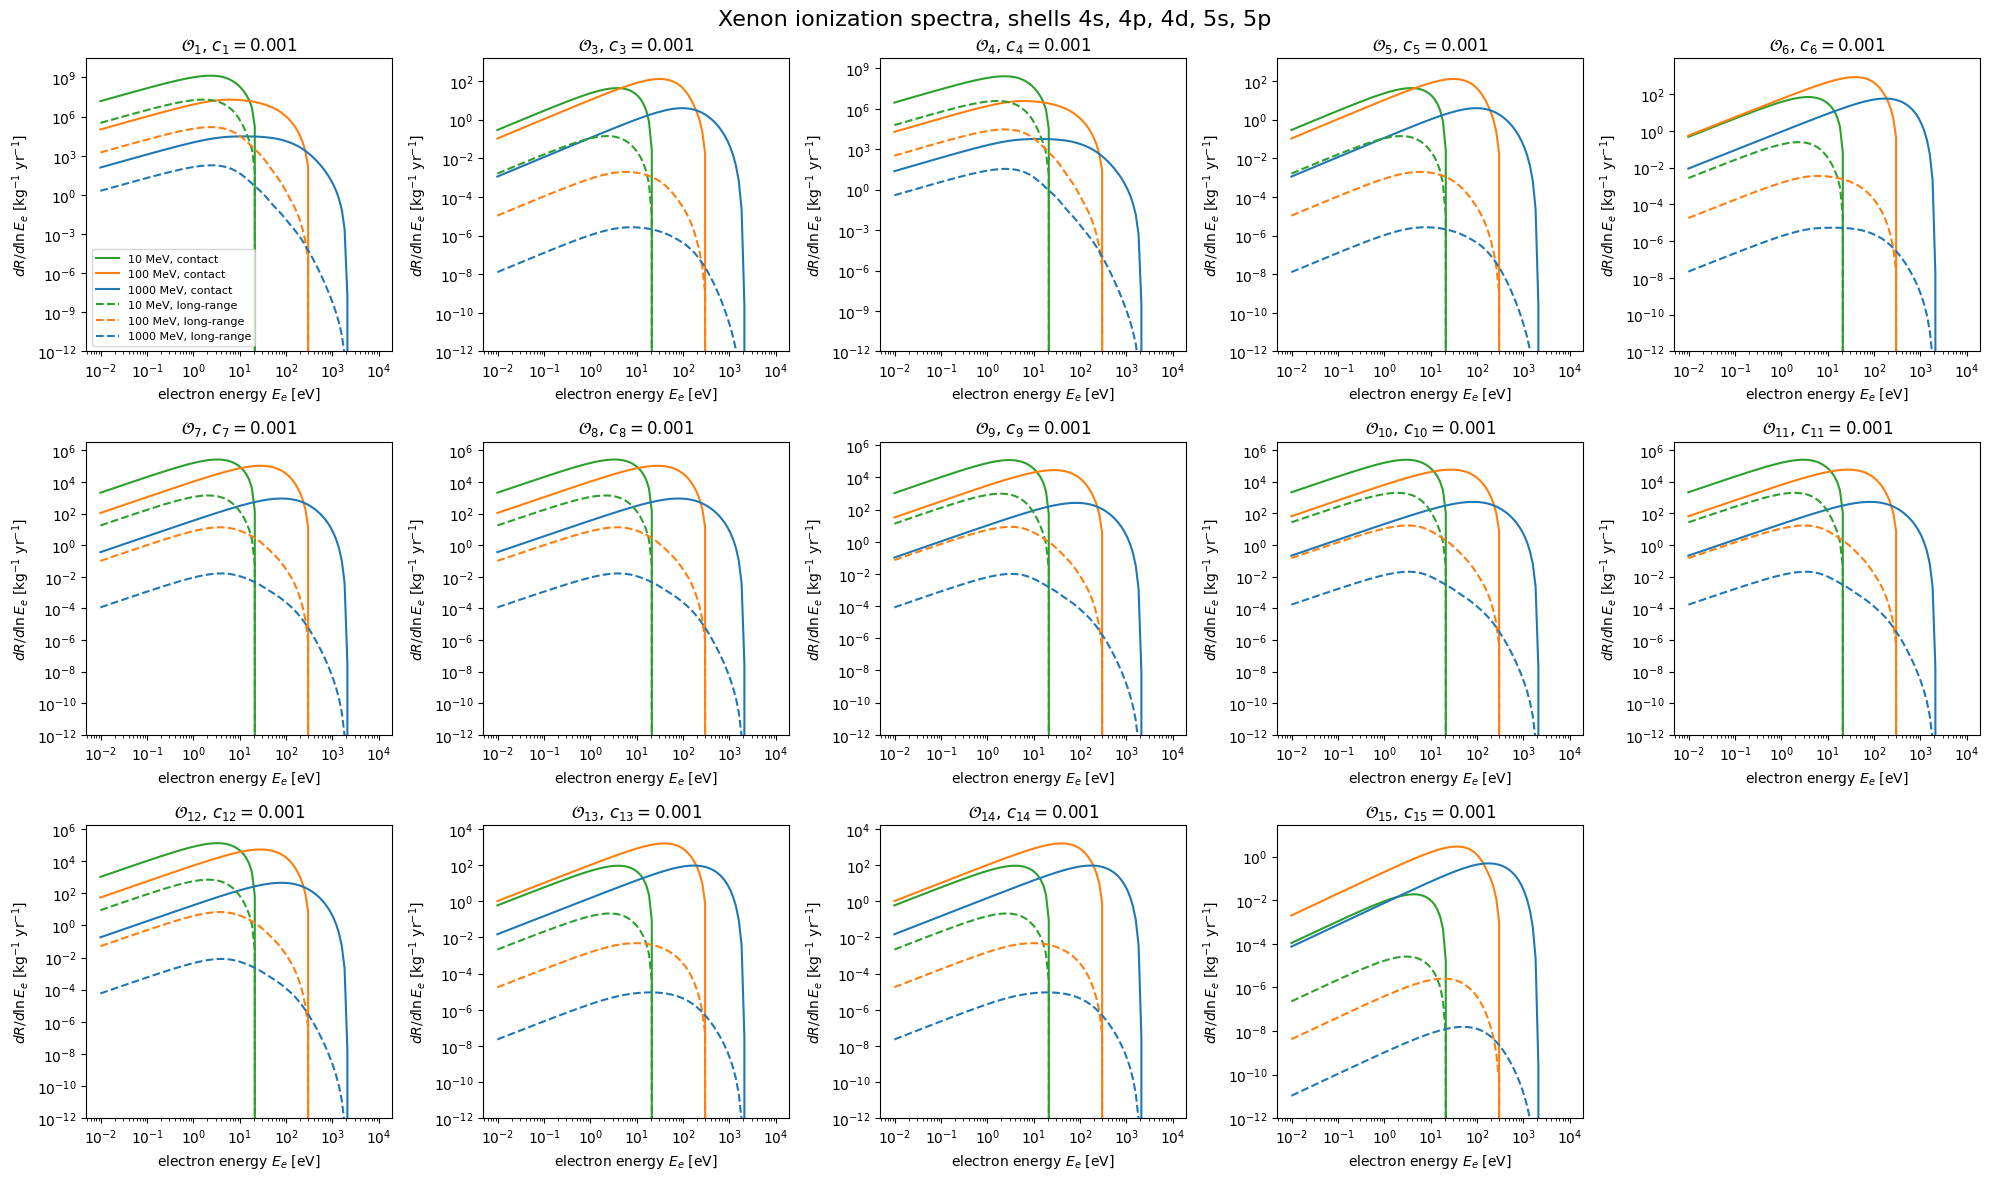

In [4]:
# plot all the NREFT spectra: solid = contact, dashed = long-range
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()
colors = {0.01: 'tab:green', 0.1: 'tab:orange', 1.0: 'tab:blue'}
for ax, i in zip(axes, NREFT_coeffs):
    for inter, ls in zip(interactions, ['-', '--']):
        for m_chi in masses:
            r = NREFT_rates[i, inter, m_chi]
            ax.plot(r['E'] * 1e3, r['dRdlnE'] * YR, ls=ls, color=colors[m_chi],
                    label=f'{m_chi*1e3:g} MeV, {inter}')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(bottom=1e-12)
    ax.set_xlabel('electron energy $E_e$ [eV]')
    ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(rf'$\mathcal{{O}}_{{{i}}}$, $c_{{{i}}} = {NREFT_coeffs[i]:g}$')
axes[0].legend(fontsize=8)
axes[-1].axis('off')
plt.suptitle(f'Xenon ionization spectra, shells {", ".join(shells)}', fontsize=16)
plt.tight_layout()
plt.show()

### Contributions of the single responses
The four terms $R_j W_j$ (Fig. 7 of the paper): `resp=j` keeps only $R_j W_j$. The contributions can be negative ($\dagger$, plotted as absolute value), e.g. $R_4 W_4$ for $\mathcal{O}_{15}$.

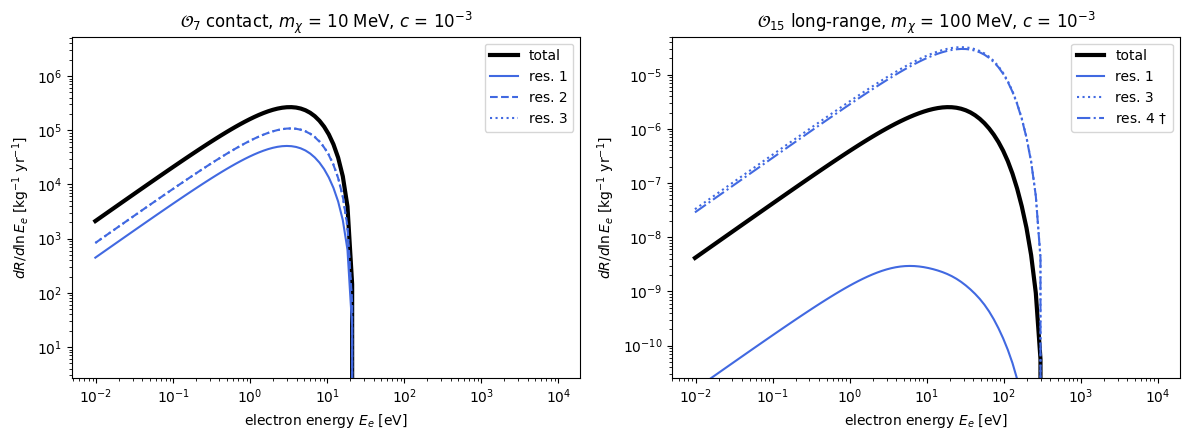

In [5]:
cases = [(7, 'contact', 0.01), (15, 'long-range', 0.1)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (i, inter, m_chi) in zip(axes, cases):
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1e-3, i, interaction=inter)
    tot = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells)
    ax.plot(tot['E'] * 1e3, tot['dRdlnE'] * YR, 'k', lw=3, label='total')
    for j, ls in zip((1, 2, 3, 4), ['-', '--', ':', '-.']):
        r = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells, resp=j)
        if np.all(r['dRdlnE'] == 0):
            continue
        neg = r['dRdlnE'].min() < 0
        ax.plot(r['E'] * 1e3, np.abs(r['dRdlnE']) * YR, ls=ls, color='royalblue',
                label=f'res. {j}' + (r' $\dagger$' if neg else ''))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(np.max(tot['dRdlnE'] * YR) * 1e-5, np.max(tot['dRdlnE'] * YR) * 20)
    ax.set_xlabel('electron energy $E_e$ [eV]')
    ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(rf'$\mathcal{{O}}_{{{i}}}$ {inter}, $m_\chi$ = {m_chi*1e3:g} MeV, $c$ = $10^{{-3}}$')
    ax.legend()
plt.tight_layout()
plt.show()

### Contributions of the Xenon shells
`dRdlnE_shell` gives the spectrum of each shell (here all the 11 shells, as in MadDM).

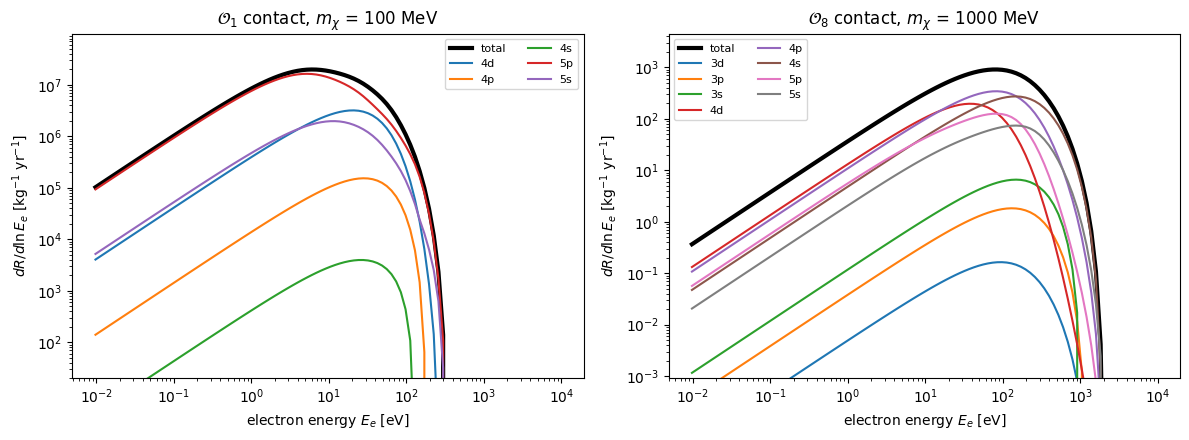

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (i, m_chi) in zip(axes, [(1, 0.1), (8, 1.0)]):
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1e-3, i)
    r = rapidd.difrate_electron(rhoDM, m_chi, jchi)  # all the shells
    ax.plot(r['E'] * 1e3, r['dRdlnE'] * YR, 'k', lw=3, label='total')
    for s, y in r['dRdlnE_shell'].items():
        if y.max() > 1e-6 * r['dRdlnE'].max():
            ax.plot(r['E'] * 1e3, y * YR, label=s)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(r['dRdlnE'].max() * YR * 1e-6, r['dRdlnE'].max() * YR * 5)
    ax.set_xlabel('electron energy $E_e$ [eV]')
    ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(rf'$\mathcal{{O}}_{{{i}}}$ contact, $m_\chi$ = {m_chi*1e3:g} MeV')
    ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## Evaluate the EFT rates
Models of Sec. IV and App. D of arXiv:1912.08204, with $e = \sqrt{4\pi\alpha}$, $g_e = 2$ and $q_\text{ref} = \alpha m_e$ (`rapidd.set_any_E_EFT_coeff(model, m_chi, coupling)`, `rapidd.set_dark_photon_coeff(m_chi, sigma_e, interaction)`):

| model | $\mathscr{L}_\text{int}$ | coupling | $c_i$ |
|:--|:--|:--|:--|
| dark photon | $\epsilon F_{\mu\nu}F'^{\mu\nu}$ | $\bar\sigma_e$ | $c_1^s = \frac{4 m_\chi m_e g_D e\epsilon}{m_{A'}^2}$ or $c_1^\ell = \frac{4 m_\chi m_e g_D e\epsilon}{q_\text{ref}^2}$ |
| anapole | $\frac{g}{2\Lambda^2}\bar\chi\gamma^\mu\gamma^5\chi\,\partial^\nu F_{\mu\nu}$ | $g/\Lambda^2$ | $c_8^s = 8 e m_e m_\chi \frac{g}{\Lambda^2}$, $c_9^s = -8 e m_e m_\chi \frac{g}{\Lambda^2}$ |
| magnetic dipole | $\frac{g}{\Lambda}\bar\psi\sigma^{\mu\nu}\psi F_{\mu\nu}$ | $g/\Lambda$ | $c_1^s = 4 e m_e \frac{g}{\Lambda}$, $c_4^s = 16 e m_\chi \frac{g}{\Lambda}$, $c_5^\ell = \frac{16 e m_e^2 m_\chi}{q_\text{ref}^2}\frac{g}{\Lambda}$, $c_6^\ell = -\frac{16 e m_e^2 m_\chi}{q_\text{ref}^2}\frac{g}{\Lambda}$ |
| electric dipole | $\frac{g}{\Lambda} i\bar\psi\sigma^{\mu\nu}\gamma^5\psi F_{\mu\nu}$ | $g/\Lambda$ | $c_{11}^\ell = \frac{16 e m_\chi m_e^2}{q_\text{ref}^2}\frac{g}{\Lambda}$ |

The reference cross section is $\bar\sigma_e = \frac{\mu_{\chi e}^2 c_i^2}{16\pi m_\chi^2 m_e^2}$ (`rapidd.sigma_e_from_coeff`, `rapidd.coeff_from_sigma_e`).

anapole {'c_8 (contact)': '1.24e-06', 'c_9 (contact)': '-1.24e-06'}
magnetic_dipole {'c_1 (contact)': '6.19e-09', 'c_4 (contact)': '4.85e-06', 'c_5 (long-range)': '0.091', 'c_6 (long-range)': '-0.091'}
electric_dipole {'c_11 (long-range)': '0.0091'}


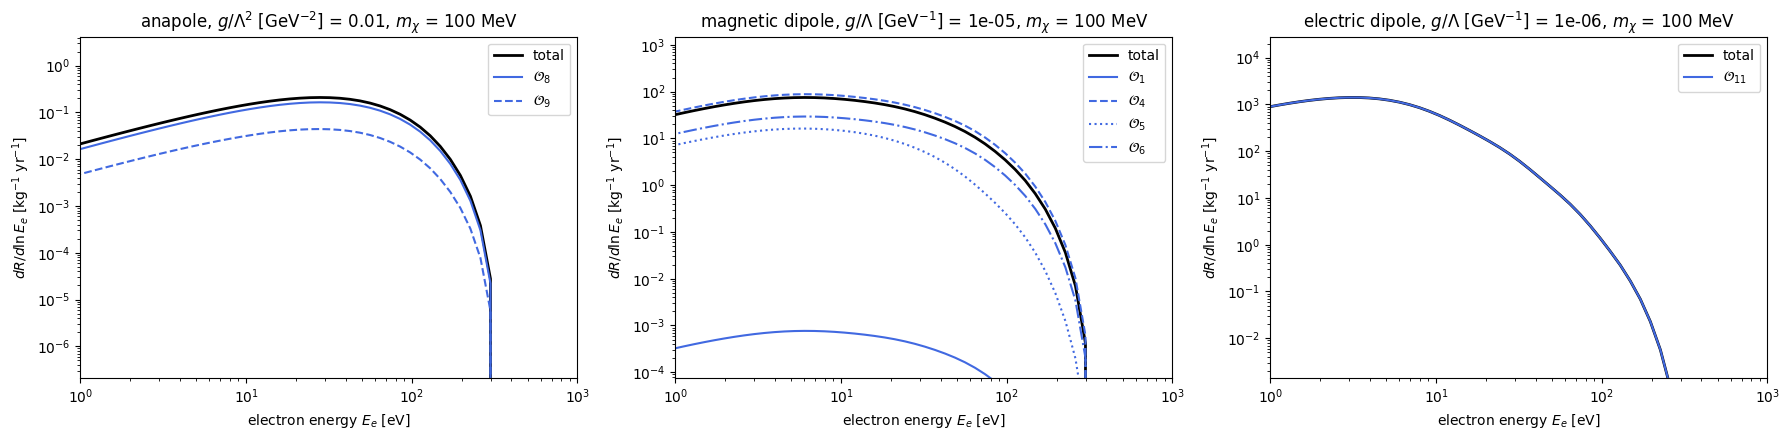

In [7]:
models = {'anapole': (1e-2, (8, 9), r'$g/\Lambda^2$ [GeV$^{-2}$]'),
          'magnetic_dipole': (1e-5, (1, 4, 5, 6), r'$g/\Lambda$ [GeV$^{-1}$]'),
          'electric_dipole': (1e-6, (11,), r'$g/\Lambda$ [GeV$^{-1}$]')}
m_chi = 0.1  # GeV
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (model, (g, ops, label)) in zip(axes, models.items()):
    rapidd.reset_coefficients()
    coeffs = rapidd.set_any_E_EFT_coeff(model, m_chi, g)
    tot = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells)
    ax.plot(tot['E'] * 1e3, tot['dRdlnE'] * YR, 'k', lw=2, label='total')
    for op, ls in zip(ops, ['-', '--', ':', '-.']):
        rapidd.reset_coefficients()
        rapidd.set_any_E_EFT_coeff(model, m_chi, g, operators=(op,))
        r = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells)
        ax.plot(r['E'] * 1e3, r['dRdlnE'] * YR, ls=ls, color='royalblue', label=rf'$\mathcal{{O}}_{{{op}}}$')
    print(model, {f'c_{op} ({inter})': f'{c:.3g}' for (op, inter), c in coeffs.items()})
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1, 1e3)
    ax.set_ylim(tot['dRdlnE'].max() * YR * 1e-6, tot['dRdlnE'].max() * YR * 20)
    ax.set_xlabel('electron energy $E_e$ [eV]')
    ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(f'{model.replace("_", " ")}, {label} = {g:g}, $m_\\chi$ = 100 MeV')
    ax.legend()
plt.tight_layout()
plt.show()

Note that for the magnetic dipole the sum of the single operators exceeds the total, because of the negative interference between $\mathcal{O}_4$ and $\mathcal{O}_6$ in $R_1$.

## Integrated rates
Total rate $\int dR/d\ln E_e\, d\ln E_e$ divided by $c_i^2$ for each operator (Fig. 6 of the paper).

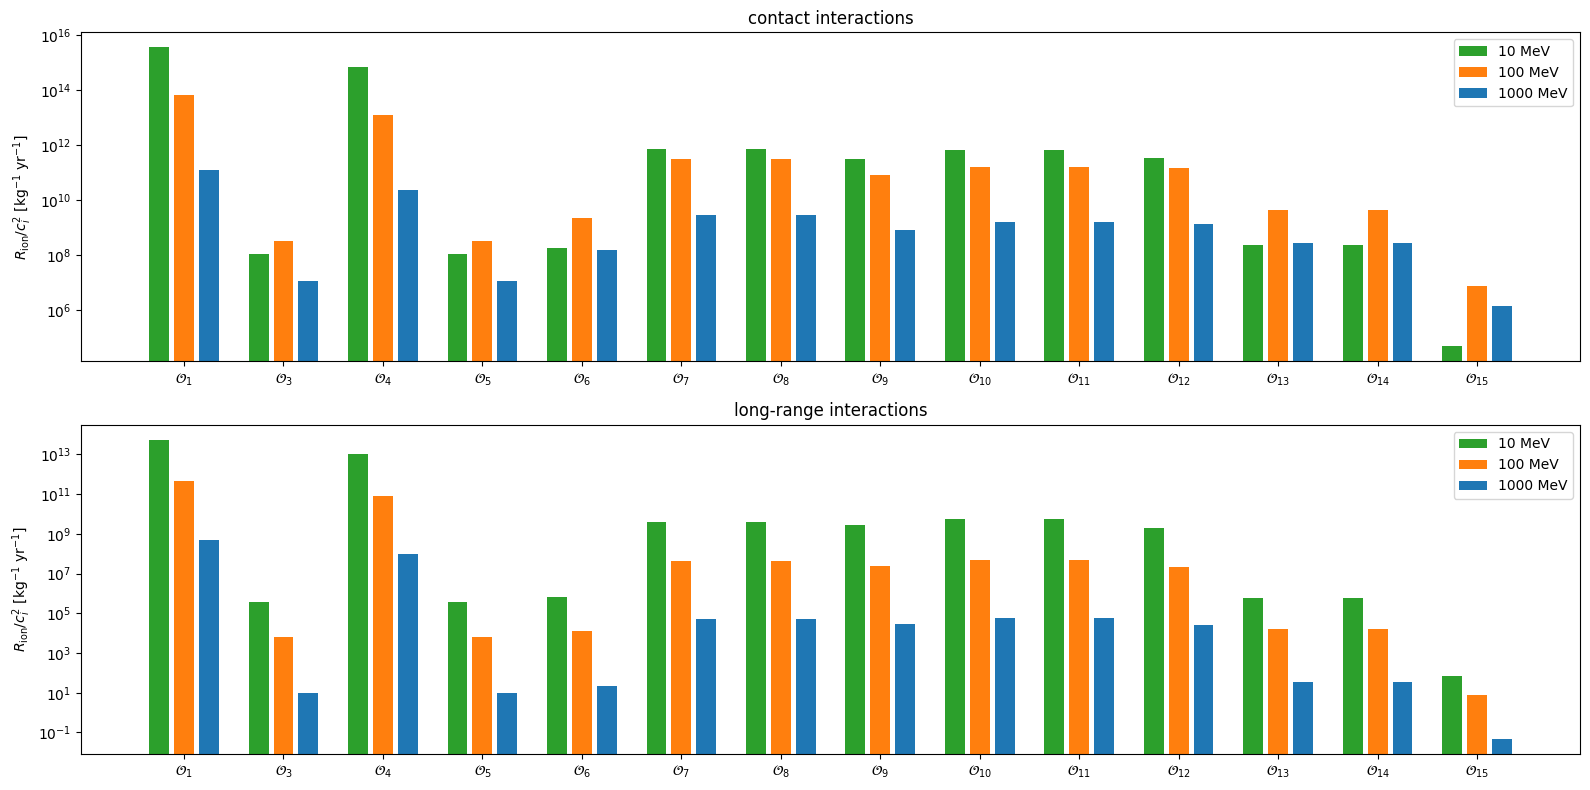

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, inter in zip(axes, interactions):
    for k, (m_chi, color) in enumerate(colors.items()):
        tot = [rapidd.total_rate_electron(None, None, rate=NREFT_rates[i, inter, m_chi]) * YR / NREFT_coeffs[i]**2
               for i in NREFT_coeffs]
        ax.bar(np.arange(len(NREFT_coeffs)) * 4 + k, tot, color=color, label=f'{m_chi*1e3:g} MeV')
    ax.set_yscale('log')
    ax.set_xticks(np.arange(len(NREFT_coeffs)) * 4 + 1)
    ax.set_xticklabels([rf'$\mathcal{{O}}_{{{i}}}$' for i in NREFT_coeffs])
    ax.set_ylabel(r'$R_\text{ion}/c_i^2$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(f'{inter} interactions')
    ax.legend()
plt.tight_layout()
plt.show()

## S2 spectra and signals
`rapidd.electron_signal` converts the per-shell spectrum into the S2 spectrum of XENON10 (7 bins, 15 kg day) and of XENON1T (S2-only data release response with efficiencies, signal in the mass dependent ROI, defined for $20\,\text{MeV} \le m_\chi \le 5\,\text{GeV}$). The secondary quanta of XENON10 use all the shells.

m = 30 MeV: c_1^s = 1.1e-06 for sigma_e = 1e-38 cm^2
m = 30 MeV: XENON10 signal [2.7816e+01 3.9540e+00 6.0100e-01 1.1500e-01 3.7000e-02 8.0000e-03
 1.0000e-03], observed [126  60  12   3   2   0   2]; XENON1T ROI signal 0.237, background 2.72, observed 9
m = 100 MeV: c_1^s = 3.61e-06 for sigma_e = 1e-38 cm^2
m = 100 MeV: XENON10 signal [14.897  4.019  1.673  1.587  1.638  1.018  0.534], observed [126  60  12   3   2   0   2]; XENON1T ROI signal 68.7, background 3.25, observed 14
m = 1000 MeV: c_1^s = 3.59e-05 for sigma_e = 1e-38 cm^2
m = 1000 MeV: XENON10 signal [1.803 0.601 0.358 0.462 0.557 0.455 0.341], observed [126  60  12   3   2   0   2]; XENON1T ROI signal 166, background 3.73, observed 16


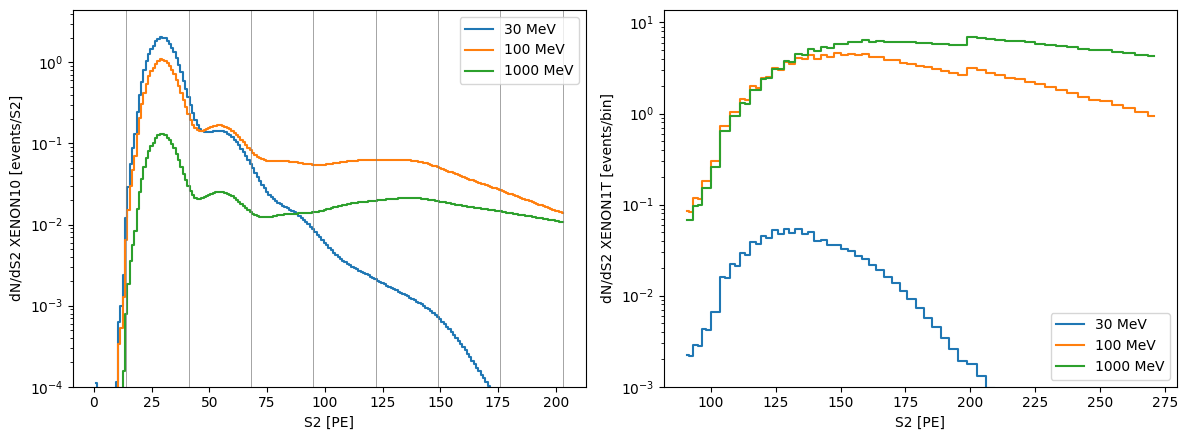

In [9]:
sigma_e = 1e-38  # cm^2, dark photon with a heavy mediator (contact c_1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m_chi in (0.03, 0.1, 1.0):
    rapidd.reset_coefficients()
    rapidd.set_dark_photon_coeff(m_chi, sigma_e)
    print(f'm = {m_chi*1e3:g} MeV: c_1^s = {rapidd.Ce_val(1):.3g} for sigma_e = {sigma_e:g} cm^2')
    rate = rapidd.difrate_electron(rhoDM, m_chi, jchi)  # all the shells
    x10 = rapidd.electron_signal('Xenon10', mDM=m_chi, rate=rate)
    x1t = rapidd.electron_signal('Xenon1T', mDM=m_chi, rate=rate)
    axes[0].step(x10['S2'], x10['dRdS2'], where='mid', label=f'{m_chi*1e3:g} MeV')
    axes[1].step(x1t['S2'], x1t['dRdS2'], where='mid', label=f'{m_chi*1e3:g} MeV')
    print(f'm = {m_chi*1e3:g} MeV: XENON10 signal {np.round(x10["signal"], 3)}, observed {x10["n_obs"]}; '
          f'XENON1T ROI signal {x1t["signal"]:.3g}, background {x1t["n_bkg"]:.3g}, observed {x1t["n_obs"]}')
for edge in rapidd.xenon10_bins():
    axes[0].axvline(edge, color='grey', lw=0.5)
for ax, exp in zip(axes, ('XENON10 [events/S2]', 'XENON1T [events/bin]')):
    ax.set_yscale('log')
    ax.set_xlabel('S2 [PE]')
    ax.set_ylabel(f'dN/dS2 {exp}')
    ax.legend()
axes[0].set_ylim(1e-4, None)
axes[1].set_ylim(1e-3, None)
plt.tight_layout()
plt.show()

## Exclusion limits (90% CL)
`rapidd.electron_limits_vs_mass` uses the scaling rate $\propto$ coupling$^2$: XENON10 with a Poisson limit in each bin independently (the strongest bin is kept, as in the paper), XENON1T with a Poisson limit in the ROI after subtracting the expected background. The paper's XENON10 limits (grey, extracted from Figs. 8 and 10 in `tests/data/paper_1912.08204`) are reproduced within ~25%; for XENON1T the paper uses a different analysis (4 S2 bins, $g_2 = 33$), so only the order of magnitude can be compared.

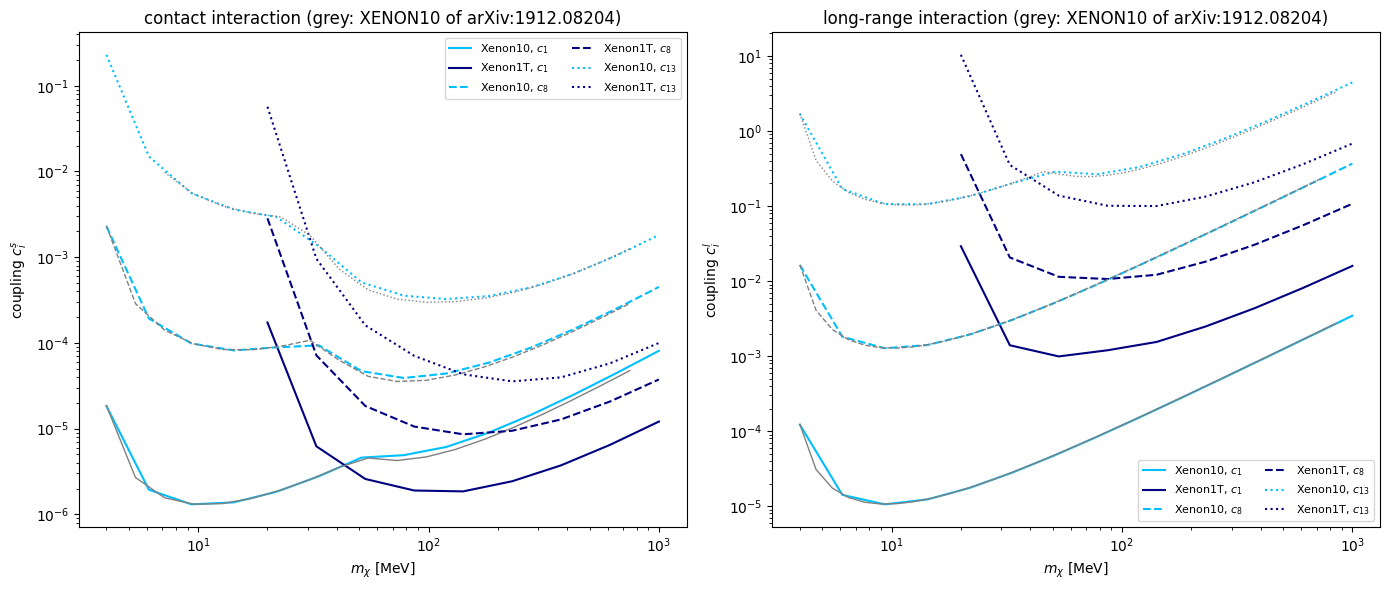

In [10]:
masses_x10 = np.geomspace(4e-3, 1., 14)
masses_x1t = np.geomspace(2e-2, 1., 9)
paper = '../tests/data/paper_1912.08204/'

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (inter, tag) in zip(axes, (('contact', 'C'), ('long-range', 'L'))):
    for op, ls in zip((1, 8, 13), ('-', '--', ':')):
        setter = lambda m, op=op, inter=inter: rapidd.set_any_Ecoeff(1., op, interaction=inter)
        for exp, masses, color in (('Xenon10', masses_x10, 'deepskyblue'), ('Xenon1T', masses_x1t, 'navy')):
            lim = rapidd.electron_limits_vs_mass(exp, masses, setter, rhoDM=rhoDM, jchi=jchi, shells=shells)
            ax.plot(masses * 1e3, lim, ls=ls, color=color, label=f'{exp}, $c_{{{op}}}$')
        x, y = np.loadtxt(f'{paper}Constraint_Coupling_{tag}__XENON10_c{op}.csv', delimiter=',').T
        ax.plot(x, y, ls=ls, color='grey', lw=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$m_\chi$ [MeV]')
    ax.set_ylabel(f'coupling $c_i^{{{"s" if inter == "contact" else "l"}}}$')
    ax.set_title(f'{inter} interaction (grey: XENON10 of arXiv:1912.08204)')
    ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

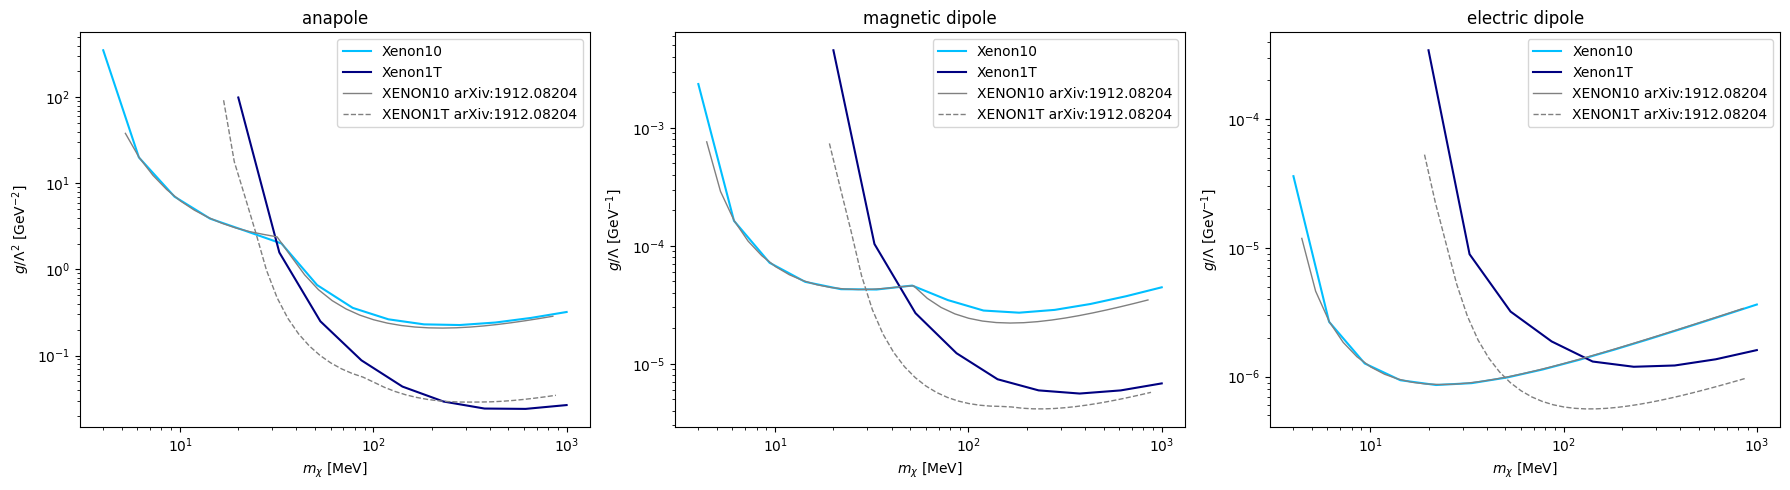

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model, (g, ops, label)) in zip(axes, models.items()):
    setter = lambda m, model=model: rapidd.set_any_E_EFT_coeff(model, m, 1.)
    for exp, masses, color in (('Xenon10', masses_x10, 'deepskyblue'), ('Xenon1T', masses_x1t, 'navy')):
        lim = rapidd.electron_limits_vs_mass(exp, masses, setter, rhoDM=rhoDM, jchi=jchi, shells=shells)
        ax.plot(masses * 1e3, lim, color=color, label=exp)
    fig_name = {'anapole': 'Anapole', 'magnetic_dipole': 'Magnetic_Dipole', 'electric_dipole': 'Electric_Dipole'}[model]
    for exp, ls in (('XENON10', '-'), ('XENON1T', '--')):
        x, y = np.loadtxt(f'{paper}Constraint_{fig_name}__{exp}.csv', delimiter=',').T
        ax.plot(x, y, ls=ls, color='grey', lw=1, label=f'{exp} arXiv:1912.08204')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$m_\chi$ [MeV]')
    ax.set_ylabel(label)
    ax.set_title(model.replace('_', ' '))
    ax.legend()
plt.tight_layout()
plt.show()
rapidd.reset_coefficients()